# MAiDE-up reproduction - Data + TF-IDF baseline
CSCI 3052U Independent Activity (Hacker / Implementer role)

Paper: Ignat, Xu & Mihalcea (2025). *MAiDE-up: Multilingual Deception Detection of AI-generated Hotel Reviews*. Findings of NAACL 2025.

Dataset: authors' public repo, https://github.com/MichiganNLP/multilingual_reviews_deception

## Upload the dataset & imports


In [ ]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

!git clone --depth 1 https://github.com/MichiganNLP/multilingual_reviews_deception.git
DATA_PATH = "multilingual_reviews_deception/data/all_data.csv"

Cloning into 'multilingual_reviews_deception'...
remote: Enumerating objects: 46, done.
remote: Counting objects: 100% (46/46), done.
remote: Compressing objects: 100% (43/43), done.
remote: Total 46 (delta 3), reused 41 (delta 3), pack-reused 0 (from 0)
Receiving objects: 100% (46/46), 9.15 MiB | 6.62 MiB/s, done.
Resolving deltas: 100% (3/3), done.
Updating files: 100% (39/39), done.


## Fixed seed

In [ ]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

## Look at the data
Label column is `source`:
* **0 = real**
* **1 = GPT-4 fake**.

In [ ]:
df = pd.read_csv(DATA_PATH)
print(df.shape)
df.head()

(19985, 12)


,Unnamed: 0,Review_Language,City Name,Hotel Name,Upside_Review,Downside_Review,Review_Score,Sentiment,source,Prompt_Language,na_up_review,na_down_review
0,0,Chinese,Ankara,迪万卡拉汉酒店,性价比超高的酒店，虽然价格比较贵，但是享受到的服务环境都还不错。,NaN,10.0,POS,0,NaN,False,True
1,1,Chinese,Ankara,迪万卡拉汉酒店,奥斯曼风格的建筑很有特色，房间装修精致，距离安卡拉城堡非常近，附近餐厅多，纪念品小商店多,不知道是不是因为夏季的原因，房间的空调不太给力，房间热；酒店员工会在窗外聊天，不考虑客人是不...,4.0,NEG,0,NaN,False,False
2,2,Chinese,Ankara,迪万卡拉汉酒店,非常喜歡酒店的環境氛圍，特別是通過地下通道到達博物館，這是一個驚喜（但入住時酒店服務人員并未...,酒店的空調令人傷心，第一天房間空調不起作用，次日上午出門時告知酒店經理，回來后依然沒有處理，...,5.0,NEG,0,NaN,False,False
3,3,Chinese,Ankara,安卡拉卡亚酒店,NaN,冷氣每隔5-15分鐘就會自動關閉，重新開啟有時候也要按三次才會開啟，飯店人員並沒有很積極地幫...,4.0,NEG,0,NaN,True,False
4,4,Chinese,Beijing,北京长城饭店(原北京喜来登长城饭店）,雖因為疫情影響加上老牌酒店旅客很少，但五星級的風骨猶存~這是寶藏好好傳承，比新酒店服務不到位強百倍,NaN,9.0,POS,0,NaN,False,True


In [ ]:
print(df["source"].value_counts())
print()
print(df["Review_Language"].value_counts())

source
1    10000
0     9985
Name: count, dtype: int64

Review_Language
English     2000
French      2000
Romanian    2000
German      2000
Italian     2000
Korean      2000
Spanish     2000
Russian     2000
Turkish     2000
Chinese     1985
Name: count, dtype: int64


The dataset contains 19,985 reviews, including 10,000 fake reviews and 9,985 real reviews. Each language has 2,000 reviews, except Chinese, which has 1,985 because 15 reviews are missing. The dataset is almost balanced, but has a small difference in the number of real and fake reviews.

## Data cleaning


In [ ]:
df.columns

Index(['Unnamed: 0', 'Review_Language', 'City Name', 'Hotel Name',
       'Upside_Review', 'Downside_Review', 'Review_Score', 'Sentiment',
       'source', 'Prompt_Language', 'na_up_review', 'na_down_review'],
      dtype='object')

In [ ]:
# Percentage of non-missing Prompt_Language values by source
print(df["Prompt_Language"].notna().groupby(df["source"]).mean() * 100)
# Percentage of missing review sections by source
print(df.groupby("source")[["na_up_review", "na_down_review"]].mean() * 100)

source
0      0.0
1    100.0
Name: Prompt_Language, dtype: float64
        na_up_review  na_down_review
source                              
0           8.322484        17.70656
1           1.650000         4.22000


### Leakage check results

**Prompt_Language:** The Prompt_Language column has values for all fake reviews (100%) but none of the real reviews (0%). This is because the column stores the language of the prompt used to generate the fake reviews. Since we want to classify reviews based on their text, including this column would cause data leakage, because it’s the language used in the prompt to generate the fake reviews.

**Hotel Name and City Name:** These columns do not describe the review itself, but the specific hotel. Since we want to classify reviews based on text, I decided to drop these columns to make sure the model doesn’t focus on some hotels/cities instead of learning from the differences between real and fake reviews.

The real reviews have a higher percentage of missing values in upside (8.32% vs. 1.65%) and downside (17.71% vs. 4.22%) than fake ones. This is most likely because GPT-4 always provides both. We’ll view them separately.

In [ ]:
# Combine the upside and downside reviews
df["text"] = df["Upside_Review"].fillna("") + " " + df["Downside_Review"].fillna("")
# Remove extra spaces
df["text"] = df["text"].str.strip()
# Remove empty reviews
df = df[df["text"] != ""]
# Select the columns we need
data = df[["text", "source", "Review_Language", "Sentiment"]]
# Rename source to label
data = data.rename(columns={"source": "label"})

print(data.shape)
data.sample(3, random_state=SEED)

(19985, 4)


,text,label,Review_Language,Sentiment
2647,emplacement sympa via del corso\nrue animée et...,0,French,POS
7626,расположение цена. небольшой запах в номере.,0,Russian,NEG
12004,L'emplacement en centre-ville est idéal Malheu...,1,French,NEG


## Train/test split
Using the same as the paper's default. The split is 80/20, 8000 real and 8000 fake for training (Section 5, Table 3).

In [ ]:
from sklearn.model_selection import train_test_split
groups = data.groupby(["label", "Review_Language"], dropna=False).ngroup()
train_df, test_df = train_test_split(
    data,
    test_size=0.2,
    random_state=SEED,
    stratify=groups
)

print("Training samples:", len(train_df))
print("Testing samples:", len(test_df))
print(train_df["label"].value_counts(normalize=True))

Training samples: 15988
Testing samples: 3997
label
1    0.500375
0    0.499625
Name: proportion, dtype: float64


In [ ]:
print(test_df["label"].value_counts(normalize=True))

label
1    0.500375
0    0.499625
Name: proportion, dtype: float64


`random_state=SEED` makes the split reproducible. The split is still random, but because of the seed, it will result in the same shuffle each time, on any computer. Otherwise, the test set would be different each time you run the code, and the accuracy would be slightly different, making it impossible for anyone to reproduce my exact numbers.


## TF-IDF Baseline

The TF-IDF algorithm converts each review to a vector of numbers, with one number for each word. TF, or term frequency, is just the count of how many times each word appears in the review. IDF, or inverse document frequency, downweights words that occur in nearly all reviews (e.g., “hotel”), and upweights words that occur in fewer reviews. The classifier then figures out which words contribute more towards classifying reviews as real versus fake.

We should only learn the vocabulary and IDF weights on the training data, otherwise we risk data leakage because our model will learn values from the test data while we’re training, leading to false accuracy.


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

vectorizer = TfidfVectorizer(max_features=50000)

X_train = vectorizer.fit_transform(train_df["text"])
X_test = vectorizer.transform(test_df["text"])
y_train = train_df["label"]
y_test = test_df["label"]

# Train Naive Bayes
nb = MultinomialNB()
nb.fit(X_train, y_train)
nb_predictions = nb.predict(X_test)

print("Naive Bayes Accuracy:", accuracy_score(y_test, nb_predictions))
print("Naive Bayes F1:", f1_score(y_test, nb_predictions))

# Train Random Forest
rf = RandomForestClassifier(
    n_estimators=200,
    random_state=SEED
)

rf.fit(X_train, y_train)
rf_predictions = rf.predict(X_test)

print("Random Forest Accuracy:", accuracy_score(y_test, rf_predictions))
print("Random Forest F1:", f1_score(y_test, rf_predictions))

Naive Bayes Accuracy: 0.8646484863647735
Naive Bayes F1: 0.8789979870275106
Random Forest Accuracy: 0.9109331998999249
Random Forest F1: 0.910055583628095



### Results vs. the Paper

| Model | Paper Accuracy | My Accuracy | Difference | Paper F1 | My F1 | Difference |
|---|---:|---:|---:|---:|---:|---:|
| Naive Bayes | 84.5% | 86.5% | +2.0 | 83.9% | 87.9% | +4.0 |
| Random Forest | 87.7% | 91.1% | +3.4 | 86.9% | 91.0% | +4.1 |

Both of my baselines performed better than the paper's. Some possible reasons may be I used Multinomial NB, which is the typical NB classifier for TF-IDF text, however the paper uses Gaussian NB. I used 200 trees instead of the scikit-learn default of 100, and I also used a different split, stratified.




## Word vs. character TF-IDF


In [ ]:
# Character-level TF-IDF
vec_char = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), max_features=50000)
X_train_char = vec_char.fit_transform(train_df["text"])
X_test_char = vec_char.transform(test_df["text"])

# Naive Bayes - Character
nb_char = MultinomialNB()
nb_char.fit(X_train_char, y_train)
nb_char_predictions = nb_char.predict(X_test_char)

# Random Forest - Character
rf_char = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1)
rf_char.fit(X_train_char, y_train)
rf_char_predictions = rf_char.predict(X_test_char)

print("Character NB accuracy:", accuracy_score(y_test, nb_char_predictions))
print("Character NB F1:", f1_score(y_test, nb_char_predictions))
print("Character RF accuracy:", accuracy_score(y_test, rf_char_predictions))
print("Character RF F1:", f1_score(y_test, rf_char_predictions))

Character NB accuracy: 0.8991743807855892
Character NB F1: 0.9052878965922444
Character RF accuracy: 0.9126845133850388
Character RF F1: 0.912945871788476


In [ ]:
# Compare both feature types on the same test set
comparison = pd.DataFrame({
    "Model": ["Naive Bayes (Word)", "Naive Bayes (Character)",
              "Random Forest (Word)", "Random Forest (Character)"],
    "Accuracy (%)": [
        accuracy_score(y_test, nb_predictions) * 100,
        accuracy_score(y_test, nb_char_predictions) * 100,
        accuracy_score(y_test, rf_predictions) * 100,
        accuracy_score(y_test, rf_char_predictions) * 100
    ],

    "F1 (%)": [
        f1_score(y_test, nb_predictions) * 100,
        f1_score(y_test, nb_char_predictions) * 100,
        f1_score(y_test, rf_predictions) * 100,
        f1_score(y_test, rf_char_predictions) * 100
    ]
})

display(comparison.round(2))

# View example of Chinese text
print("\nExample Chinese review:")
print(train_df.loc[train_df["Review_Language"] == "Chinese", "text"].iloc[0])

,Model,Accuracy (%),F1 (%)
0,Naive Bayes (Word),86.46,87.90
1,Naive Bayes (Character),89.92,90.53
2,Random Forest (Word),91.09,91.01
3,Random Forest (Character),91.27,91.29



Example Chinese review:
员工服务 设施陈旧，浴室有污迹， 隔音太差


## Word vs character: analysis

I compared word-level and character-level TF-IDF features using Naive Bayes and Random Forest.

Naive Bayes improved from 86.46% to 89.92% accuracy when I used character features. However, Random Forest showed only a little increase, from 91.09% to 91.27%.

An explanation is that character-level features are better to deal with languages like Chinese, since Chinese does not generally use space to separate words. TF-IDF at the word level might not pick up on meaningful word patterns . Character n-grams can pick up on smaller sequences without having to rely on word boundaries .

In conclusion, character-level features helped Naive Bayes a lot and Random Forest only by a little.

## Random Forest accuracy by language

In [ ]:
test_df = test_df.assign(pred=rf_predictions)
language_accuracy = test_df.groupby("Review_Language").apply(
    lambda g: (g["pred"] == g["label"]).mean() * 100
).sort_values()
language_accuracy

/tmp/ipykernel_14081/4218461992.py:2: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  language_accuracy = test_df.groupby("Review_Language").apply(


,0
Review_Language,
Chinese,80.352645
Korean,89.750000
German,90.250000
English,90.250000
Romanian,91.750000
Russian,93.250000
Turkish,93.250000
French,93.500000
Italian,94.000000


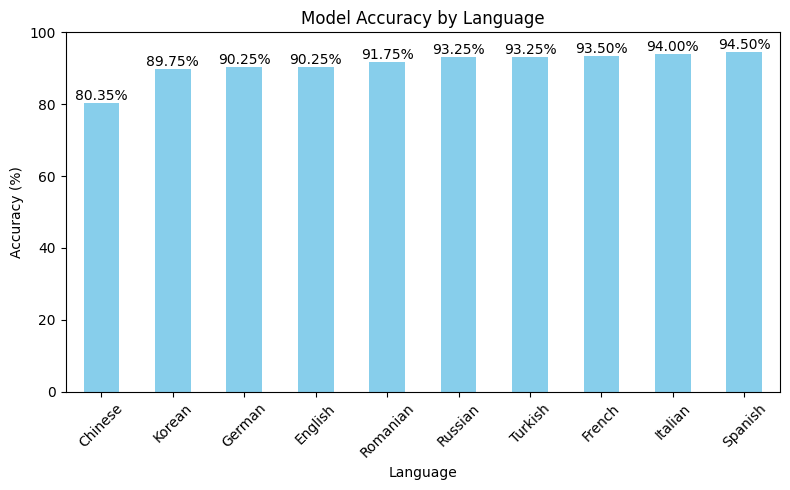

In [ ]:
ax = language_accuracy.plot(
    kind="bar",
    figsize=(8, 5),
    color="skyblue"
)

ax.bar_label(
    ax.containers[0],
    fmt="%.2f%%"
)

plt.title("Model Accuracy by Language")
plt.ylabel("Accuracy (%)")
plt.xlabel("Language")
plt.ylim(0, 100)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## Word vs character accuracy by language

In [ ]:
# Character-level Random Forest accuracy by language
test_df = test_df.assign(pred_char=rf_char_predictions)

char_language_accuracy = test_df.groupby("Review_Language").apply(
    lambda g: (g["pred_char"] == g["label"]).mean() * 100
).sort_values()

char_language_accuracy

/tmp/ipykernel_14081/1994170633.py:4: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  char_language_accuracy = test_df.groupby("Review_Language").apply(


,0
Review_Language,
English,87.00000
German,88.75000
Romanian,90.00000
French,90.75000
Chinese,90.93199
Italian,92.25000
Korean,92.25000
Spanish,92.75000
Russian,93.75000


In [ ]:
# Compare word and character results by language
language_comparison = pd.DataFrame({
    "Word RF (%)": language_accuracy,
    "Character RF (%)": char_language_accuracy
})

language_comparison["Difference (pp)"] = (
    language_comparison["Character RF (%)"] - language_comparison["Word RF (%)"]
)

display(language_comparison.round(2))

# Check how much Chinese accuracy changed
print("Chinese word accuracy:", round(language_accuracy["Chinese"], 2))
print("Chinese character accuracy:", round(char_language_accuracy["Chinese"], 2))

,Word RF (%),Character RF (%),Difference (pp)
Review_Language,,,
Chinese,80.35,90.93,10.58
English,90.25,87.00,-3.25
French,93.50,90.75,-2.75
German,90.25,88.75,-1.50
Italian,94.00,92.25,-1.75
Korean,89.75,92.25,2.50
Romanian,91.75,90.00,-1.75
Russian,93.25,93.75,0.50
Spanish,94.50,92.75,-1.75


Chinese word accuracy: 80.35
Chinese character accuracy: 90.93


## Accuracy by Language

I examined the word-level Random Forest separately for each language to see how it differs.

Chinese performed the worst with an 80.35% accuracy, followed by Korean with 89.75%. English and German scored 90.25% each, while Spanish and Italian were the best, scoring 94.50% and 94.00% respectively.

These findings are a little consistent with Figure 3a of the paper showing Korean and English as the most difficult languages. However, the paper found German and Romanian to be among the easiest, but my results ranked them lower.

A possible reason for the poor performance on Chinese reviews is word-level tokenization. TF-IDF may have difficulty in capturing meaningful patterns since Chinese usually does not use spaces to mark word boundaries.

To test this, I compared the character-level Random Forest and word-level results for each language. Chinese accuracy increased by 10.58 percentage points. Korean also increased 2.5 precentage points. Some languages, however, like English, did worse on the character features.

It shows that the character-level features are more suitable to capture patterns in languages like Chinese, though tokenization may not be the only factor that impacts the performance.

## Leakage Test

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Retrieve blank-review indicators from the original df using indices
X_train_blank = df.loc[train_df.index, ["na_up_review", "na_down_review"]]
X_test_blank = df.loc[test_df.index, ["na_up_review", "na_down_review"]]

# Train baseline model
blank_model = LogisticRegression(random_state=SEED)
blank_model.fit(X_train_blank, y_train)

# Generate predictions
y_pred = blank_model.predict(X_test_blank)

# Evaluate accuracy
accuracy = accuracy_score(y_test, y_pred)

print(f"Blank-only accuracy: {accuracy:.2%}")

Blank-only accuracy: 60.07%


## Leakage Test: analysis
To determine if there is any data leakage I trained a Logistic Regression model using only two features: the blankness of the upside and downside sections of a review.

The model achieved 60.07% accuracy, despite never looking at the actual review text. The set baseline was 50% - random guessing.

It implies that there are more patterns in the dataset except the writing style that can distinguish between human and AI written reviews. For example, human reviewers tend to leave some sections blank.

This does not demonstrate that the primary models rely on these patterns, but it suggests a potential dataset bias that could affect our interpretation of their performance.

It is worth asking whether AI detection models are learning real linguistic differences, or whether they are in part relying on dataset-specific patterns.